# Perhitungan Volume Kedua Lambung Kapal

**Nama:** Faishal Rabbani    
**NPM:** [25083010024]  
**Kelas:** [A083]  
**Mata Kuliah:** Analisis Numerik  
 
**Github:** 

# Perhitungan Volume Kedua Lambung Kapal

Pada tugas ini, kita akan menghitung volume kedua lambung kapal menggunakan integrasi numerik.

Sesuai dengan instruksi soal, satu jarak pada grid bernilai:

$$
5 + 5 = 10\text{ cm}
$$

Lantai kapal dianggap datar sehingga penampang lambung dapat dianggap berbentuk persegi panjang. Bagian **reserve buoyancy tidak dihitung**.

Kita akan menggunakan dua metode numerik:
1. Metode Trapesium
2. Metode Simpson 1/3

## 1. Memasukkan Data

Pertama, kita tentukan posisi penampang sepanjang kapal.

Karena jarak antar titik pada grid adalah 10 cm dan terdapat 20 interval, maka terdapat 21 titik pengamatan.

Untuk setiap titik, kita membaca:
- lebar lambung dari tampak atas
- tinggi lambung dari tampak samping

Kemudian kedua nilai tersebut digunakan untuk menghitung luas penampang.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Jarak antar titik
h = 10  # cm

# Posisi sepanjang kapal
x = np.arange(0, 201, 10)

# Lebar lambung (cm)
width = np.array([
    11, 14, 17, 18, 19, 19, 20, 20, 20, 20,
    20, 20, 20, 20, 19, 19, 17, 15, 12, 9, 4
])

# Tinggi lambung (cm)
height = np.array([
     8, 13, 17, 21, 24, 25, 25, 25, 25, 25,
    25, 25, 25, 25, 25, 25, 25, 25, 24, 18, 8
])

print("Jumlah titik :", len(x))
print("Jumlah interval :", len(x) - 1)
print("Jarak antar titik :", h, "cm")

Jumlah titik : 21
Jumlah interval : 20
Jarak antar titik : 10 cm


### Sampai sini aman?

Kita memiliki 21 titik, sehingga jumlah intervalnya adalah 20.

Karena jarak antar titik selalu sama, yaitu 10 cm, data ini sudah bisa digunakan untuk integrasi numerik.

## 2. Menghitung Luas Penampang

Karena tampak depan lambung dianggap berbentuk persegi panjang, luas penampang pada setiap titik dihitung dengan:

$$
A_i = b_i \times t_i
$$

dengan:
- $A_i$ = luas penampang ke-$i$ (cm²)
- $b_i$ = lebar lambung (cm)
- $t_i$ = tinggi lambung (cm)

In [33]:
# Menghitung luas penampang
A = width * height

data = pd.DataFrame({
    "Posisi (cm)": x,
    "Lebar (cm)": width,
    "Tinggi (cm)": height,
    "Luas Penampang (cm²)": A
})

data

,Posisi (cm),Lebar (cm),Tinggi (cm),Luas Penampang (cm²)
0,0,11,8,88
1,10,14,13,182
2,20,17,17,289
3,30,18,21,378
4,40,19,24,456
5,50,19,25,475
6,60,20,25,500
7,70,20,25,500
8,80,20,25,500
9,90,20,25,500


### Coba kita lihat tabelnya

Terlihat bahwa luas penampang semakin besar ketika memasuki bagian tengah kapal.

Sebaliknya, luasnya kembali mengecil ketika mendekati ujung kapal.

Nah, luas penampang inilah yang akan kita integralkan sepanjang kapal untuk mendapatkan volumenya.

## 3. Grafik Luas Penampang

Sebelum menghitung volume, kita lihat dulu bagaimana perubahan luas penampang sepanjang kapal.

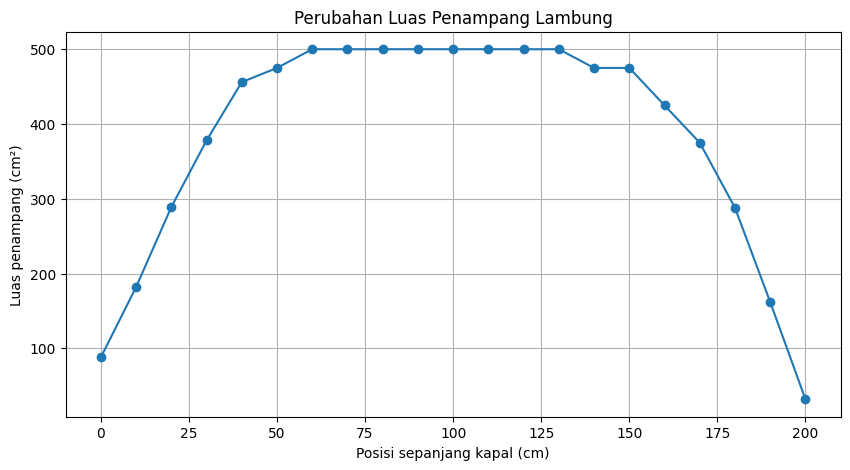

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(x, A, marker='o')

plt.xlabel("Posisi sepanjang kapal (cm)")
plt.ylabel("Luas penampang (cm²)")
plt.title("Perubahan Luas Penampang Lambung")
plt.grid(True)

plt.show()

### Dari grafik ini kita bisa melihat...

Bagian tengah kapal memiliki luas penampang yang relatif besar, sedangkan bagian depan dan belakang semakin mengecil.

Karena bentuknya tidak berupa satu luas yang konstan, kita membutuhkan integrasi numerik untuk memperkirakan volumenya.

## 4. Metode Trapesium

Sekarang kita mulai menghitung volume menggunakan metode Trapesium.

Rumus yang digunakan adalah:

$$
V \approx h
\left[
\frac{A_0 + A_n}{2}
+
\sum_{i=1}^{n-1} A_i
\right]
$$

Dengan jarak antar titik:

$$
h = 10\text{ cm}
$$

Perhitungan ini menghasilkan volume untuk **satu lambung kapal**.

In [35]:
V_trapesium = h * (
    (A[0] + A[-1]) / 2
    + np.sum(A[1:-1])
)

print(f"Volume 1 lambung = {V_trapesium:.2f} cm³")

Volume 1 lambung = 80400.00 cm³


### Bagaimana hasilnya?

Dari metode Trapesium, kita mendapatkan volume sekitar **80.400 cm³ untuk satu lambung**.

Karena kapal memiliki dua lambung yang diasumsikan memiliki bentuk yang sama, hasil ini akan kita kalikan dua.

In [36]:
V_trapesium_2 = 2 * V_trapesium

print(f"Volume 2 lambung = {V_trapesium_2:.2f} cm³")
print(f"Volume 2 lambung = {V_trapesium_2 / 1000:.2f} liter")

Volume 2 lambung = 160800.00 cm³
Volume 2 lambung = 160.80 liter


Jadi, dengan metode Trapesium, volume kedua lambung adalah sekitar **160,80 liter**.

Sekarang kita coba metode kedua untuk melihat apakah hasilnya tetap mendekati angka tersebut.

## 5. Metode Simpson 1/3

Selanjutnya kita gunakan metode Simpson 1/3.

Metode ini menggunakan bobot 4 dan 2 pada titik-titik tertentu.

Rumusnya:

$$
V \approx
\frac{h}{3}
\left[
A_0 + A_n
+ 4(A_1 + A_3 + A_5 + \cdots + A_{n-1})
+ 2(A_2 + A_4 + A_6 + \cdots + A_{n-2})
\right]
$$

Jumlah interval kita adalah 20, sehingga memenuhi syarat untuk menggunakan metode Simpson 1/3.

In [37]:
n = len(A) - 1

if n % 2 != 0:
    raise ValueError("Jumlah interval harus genap.")

V_simpson13 = (h / 3) * (
    A[0]
    + A[-1]
    + 4 * np.sum(A[1:-1:2])
    + 2 * np.sum(A[2:-1:2])
)

print(f"Volume 1 lambung = {V_simpson13:.2f} cm³")

Volume 1 lambung = 80580.00 cm³


### Nah, apakah hasilnya jauh berbeda?

Ternyata hasil Simpson 1/3 sangat dekat dengan metode Trapesium.

Untuk satu lambung, hasilnya sekitar **80.580 cm³**.

Sekarang kita kalikan dengan dua untuk mendapatkan volume kedua lambung.

In [38]:
V_simpson13_2 = 2 * V_simpson13

print(f"Volume 2 lambung = {V_simpson13_2:.2f} cm³")
print(f"Volume 2 lambung = {V_simpson13_2 / 1000:.2f} liter")

Volume 2 lambung = 161160.00 cm³
Volume 2 lambung = 161.16 liter


## 6. Perbandingan Hasil

Sekarang kita sudah mendapatkan hasil dari dua metode.

Daripada melihatnya satu per satu, kita buat tabel perbandingan agar lebih mudah dilihat.

In [39]:
hasil = pd.DataFrame({
    "Metode": [
        "Trapesium",
        "Simpson 1/3"
    ],
    "1 Lambung (cm³)": [
        V_trapesium,
        V_simpson13
    ],
    "2 Lambung (cm³)": [
        V_trapesium_2,
        V_simpson13_2
    ],
    "2 Lambung (Liter)": [
        V_trapesium_2 / 1000,
        V_simpson13_2 / 1000
    ]
})

hasil

,Metode,1 Lambung (cm³),2 Lambung (cm³),2 Lambung (Liter)
0,Trapesium,80400.0,160800.0,160.80
1,Simpson 1/3,80580.0,161160.0,161.16


### Jadi, hasil akhirnya berapa?

Hasil kedua metode ternyata sangat berdekatan:

- **Trapesium = 160,80 liter**
- **Simpson 1/3 = 161,16 liter**

Selisihnya hanya sekitar **0,36 liter**.

Artinya, kedua metode memberikan hasil yang cukup konsisten untuk data penampang yang kita gunakan.

Jadi, berdasarkan pembacaan grid pada gambar, volume kedua lambung kapal diperkirakan sekitar **161 liter**.

## 7. Kesimpulan

Berdasarkan perhitungan integrasi numerik, diperoleh volume kedua lambung kapal sekitar:

$$
\boxed{160,80 - 161,16\text{ liter}}
$$

Hasil metode Trapesium dan Simpson 1/3 memiliki perbedaan yang kecil, sehingga hasil perhitungan dapat dikatakan cukup konsisten.

Perlu diingat bahwa nilai ini merupakan pendekatan berdasarkan pembacaan ukuran dari grid pada gambar.